In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import os

In [2]:
# 1. Define paths and memory parameters
folder_path =r"C:\Users\User\Downloads\linkedin_dataset"
ROWS_TO_LOAD = 30000  # Limits rows per file so my computer doesn't crash or run out of RAM

In [3]:
# check folder exists
print(os.path.exists(folder_path))

# walk through all files
for root, dirs, files in os.walk(folder_path):
    # print each file with size in MB
    for f in files:
        full = os.path.join(root, f)
        print(full, round(os.path.getsize(full) / 1e6, 1), "MB")

True
C:\Users\User\Downloads\linkedin_dataset\postings.csv 516.8 MB
C:\Users\User\Downloads\linkedin_dataset\companies\companies.csv 23.2 MB
C:\Users\User\Downloads\linkedin_dataset\companies\company_industries.csv 0.8 MB
C:\Users\User\Downloads\linkedin_dataset\companies\company_specialities.csv 4.4 MB
C:\Users\User\Downloads\linkedin_dataset\companies\employee_counts.csv 1.0 MB
C:\Users\User\Downloads\linkedin_dataset\jobs\benefits.csv 1.9 MB
C:\Users\User\Downloads\linkedin_dataset\jobs\job_industries.csv 2.5 MB
C:\Users\User\Downloads\linkedin_dataset\jobs\job_skills.csv 3.5 MB
C:\Users\User\Downloads\linkedin_dataset\jobs\salaries.csv 2.3 MB
C:\Users\User\Downloads\linkedin_dataset\mappings\industries.csv 0.0 MB
C:\Users\User\Downloads\linkedin_dataset\mappings\skills.csv 0.0 MB


In [4]:
# full path to postings
postings_path = os.path.join(folder_path, "postings.csv")

# load 5 rows only
job= pd.read_csv(postings_path, nrows=5)

In [5]:
# show shape
print(job.shape)

(5, 31)


In [6]:
# show column names
list(job.columns)

['job_id',
 'company_name',
 'title',
 'description',
 'max_salary',
 'pay_period',
 'location',
 'company_id',
 'views',
 'med_salary',
 'min_salary',
 'formatted_work_type',
 'applies',
 'original_listed_time',
 'remote_allowed',
 'job_posting_url',
 'application_url',
 'application_type',
 'expiry',
 'closed_time',
 'formatted_experience_level',
 'skills_desc',
 'listed_time',
 'posting_domain',
 'sponsored',
 'work_type',
 'currency',
 'compensation_type',
 'normalized_salary',
 'zip_code',
 'fips']

In [7]:
# preview rows
job.head()

,job_id,company_name,title,description,max_salary,pay_period,location,company_id,views,med_salary,...,skills_desc,listed_time,posting_domain,sponsored,work_type,currency,compensation_type,normalized_salary,zip_code,fips
0,921716,Corcoran Sawyer Smith,Marketing Coordinator,Job descriptionA leading real estate firm in N...,20.0,HOURLY,"Princeton, NJ",2774458.0,20.0,NaN,...,Requirements: \n\nWe are seeking a College or ...,1.713398e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,38480.0,8540,34021
1,1829192,NaN,Mental Health Therapist/Counselor,"At Aspen Therapy and Wellness , we are committ...",50.0,HOURLY,"Fort Collins, CO",NaN,1.0,NaN,...,NaN,1.712858e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,83200.0,80521,8069
2,10998357,The National Exemplar,Assitant Restaurant Manager,The National Exemplar is accepting application...,65000.0,YEARLY,"Cincinnati, OH",64896719.0,8.0,NaN,...,We are currently accepting resumes for FOH - A...,1.713278e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,55000.0,45202,39061
3,23221523,"Abrams Fensterman, LLP",Senior Elder Law / Trusts and Estates Associat...,Senior Associate Attorney - Elder Law / Trusts...,175000.0,YEARLY,"New Hyde Park, NY",766262.0,16.0,NaN,...,This position requires a baseline understandin...,1.712896e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,157500.0,11040,36059
4,35982263,NaN,Service Technician,Looking for HVAC service tech with experience ...,80000.0,YEARLY,"Burlington, IA",NaN,3.0,NaN,...,NaN,1.713452e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,70000.0,52601,19057


In [8]:
job.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 31 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   job_id                      5 non-null      int64  
 1   company_name                3 non-null      object 
 2   title                       5 non-null      object 
 3   description                 5 non-null      object 
 4   max_salary                  5 non-null      float64
 5   pay_period                  5 non-null      object 
 6   location                    5 non-null      object 
 7   company_id                  3 non-null      float64
 8   views                       5 non-null      float64
 9   med_salary                  0 non-null      float64
 10  min_salary                  5 non-null      float64
 11  formatted_work_type         5 non-null      object 
 12  applies                     1 non-null      float64
 13  original_listed_time        5 non-null 

In [9]:
# unique values per column
job.nunique()

job_id                        5
company_name                  3
title                         5
description                   5
max_salary                    5
pay_period                    2
location                      5
company_id                    3
views                         5
med_salary                    0
min_salary                    5
formatted_work_type           1
applies                       1
original_listed_time          5
remote_allowed                0
job_posting_url               5
application_url               0
application_type              1
expiry                        5
closed_time                   0
formatted_experience_level    0
skills_desc                   3
listed_time                   5
posting_domain                0
sponsored                     1
work_type                     1
currency                      1
compensation_type             1
normalized_salary             5
zip_code                      5
fips                          5
dtype: i

In [10]:
 #work type counts
job["formatted_work_type"].value_counts()

formatted_work_type
Full-time    5
Name: count, dtype: int64

In [11]:
# columns to keep
cols = ["job_id", "company_name", "title", "description", "skills_desc",
        "formatted_experience_level", "location", "formatted_work_type"]

# empty list to hold samples
parts = []

# read file in chunks of 50,000 rows
for chunk in pd.read_csv(postings_path, usecols=cols, chunksize=50000):
    # random 25% of this chunk
    parts.append(chunk.sample(frac=0.25, random_state=42))

# join all samples into wm
wm = pd.concat(parts, ignore_index=True)

# show shape
print(wm.shape)

(30962, 8)


In [12]:
# rename description to job_description
wm = wm.rename(columns={"description": "job_description"})

# check new column names
print(list(wm.columns))

['job_id', 'company_name', 'title', 'job_description', 'location', 'formatted_work_type', 'formatted_experience_level', 'skills_desc']


In [13]:
# show column types
wm.dtypes

job_id                         int64
company_name                  object
title                         object
job_description               object
location                      object
formatted_work_type           object
formatted_experience_level    object
skills_desc                   object
dtype: object

In [14]:
job.describe()

,job_id,max_salary,company_id,views,med_salary,min_salary,applies,original_listed_time,remote_allowed,application_url,expiry,closed_time,formatted_experience_level,listed_time,posting_domain,sponsored,normalized_salary,zip_code,fips
count,5.000000e+00,5.000000,3.000000e+00,5.000000,0.0,5.000000,1.0,5.000000e+00,0.0,0.0,5.000000e+00,0.0,0.0,5.000000e+00,0.0,5.0,5.000000,5.000000,5.000000
mean,1.459061e+07,64014.000000,2.281248e+07,9.600000,NaN,49009.400000,2.0,1.713176e+12,NaN,NaN,1.715768e+12,NaN,NaN,1.713176e+12,NaN,0.0,80836.000000,39580.800000,27253.400000
std,1.495570e+07,72043.462438,3.645985e+07,8.203658,NaN,57479.115223,NaN,2.807298e+08,NaN,NaN,2.807298e+08,NaN,NaN,2.807298e+08,NaN,0.0,45994.309213,30229.670867,13209.661192
min,9.217160e+05,20.000000,7.662620e+05,1.000000,NaN,17.000000,2.0,1.712858e+12,NaN,NaN,1.715450e+12,NaN,NaN,1.712858e+12,NaN,0.0,38480.000000,8540.000000,8069.000000
25%,1.829192e+06,50.000000,1.770360e+06,3.000000,NaN,30.000000,2.0,1.712896e+12,NaN,NaN,1.715488e+12,NaN,NaN,1.712896e+12,NaN,0.0,55000.000000,11040.000000,19057.000000
50%,1.099836e+07,65000.000000,2.774458e+06,8.000000,NaN,45000.000000,2.0,1.713278e+12,NaN,NaN,1.715870e+12,NaN,NaN,1.713278e+12,NaN,0.0,70000.000000,45202.000000,34021.000000
75%,2.322152e+07,80000.000000,3.383559e+07,16.000000,NaN,60000.000000,2.0,1.713398e+12,NaN,NaN,1.715990e+12,NaN,NaN,1.713398e+12,NaN,0.0,83200.000000,52601.000000,36059.000000
max,3.598226e+07,175000.000000,6.489672e+07,20.000000,NaN,140000.000000,2.0,1.713452e+12,NaN,NaN,1.716044e+12,NaN,NaN,1.713452e+12,NaN,0.0,157500.000000,80521.000000,39061.000000


In [15]:
# count blanks per column
wm.isnull().sum()

job_id                            0
company_name                    442
title                             0
job_description                   2
location                          0
formatted_work_type               0
formatted_experience_level     7288
skills_desc                   30361
dtype: int64

In [16]:
# count duplicate job_id
print("dup job_id:", wm.duplicated(subset="job_id").sum())

dup job_id: 0


In [17]:
# count duplicate title + description
print("dup title+desc:", wm.duplicated(subset=["title", "job_description"]).sum())

dup title+desc: 1699


### Dropping `skills_desc`

`skills_desc` was blank in 30,361 of 30,962 rows (98.1%), so only 601 rows had any skills text. It was dropped because it is too empty to help the model.

In [18]:
# drop skills_desc
wm = wm.drop(columns=["skills_desc"])

In [19]:
# check columns
list(wm.columns)

['job_id',
 'company_name',
 'title',
 'job_description',
 'location',
 'formatted_work_type',
 'formatted_experience_level']

In [20]:
wm.shape

(30962, 7)

In [21]:
# experience level counts (incl. blanks)
print(wm["formatted_experience_level"].value_counts(dropna=False))

formatted_experience_level
Mid-Senior level    10501
Entry level          9054
NaN                  7288
Associate            2525
Director              920
Internship            348
Executive             326
Name: count, dtype: int64


In [22]:
# unique values per column
wm.nunique()

job_id                        30962
company_name                  10513
title                         22061
job_description               28819
location                       4854
formatted_work_type               7
formatted_experience_level        6
dtype: int64

In [23]:
# work type counts
print(wm["formatted_work_type"].value_counts())

formatted_work_type
Full-time     24695
Contract       3088
Part-time      2367
Temporary       306
Internship      250
Other           129
Volunteer       127
Name: count, dtype: int64


In [24]:
# top 10 locations
print(wm["location"].value_counts().head(10))

location
United States      2046
New York, NY        673
Chicago, IL         484
Houston, TX         474
Dallas, TX          356
Atlanta, GA         353
Boston, MA          318
Los Angeles, CA     269
Austin, TX          269
Phoenix, AZ         258
Name: count, dtype: int64


### Data Cleaning

In [25]:
# rows before cleaning
print("before:", wm.shape)

before: (30962, 7)


In [26]:
# drop rows with blank description
wm = wm.dropna(subset=["job_description"])

In [27]:
# drop repeats of title + description, keep first
wm = wm.drop_duplicates(subset=["title", "job_description"], keep="first")

In [28]:
# reset row numbers
wm = wm.reset_index(drop=True)

In [29]:
# rows after cleaning
print("after:", wm.shape)

after: (29261, 7)


In [30]:
# fill blank company
wm["company_name"] = wm["company_name"].fillna("Unknown")

In [31]:
# strip spaces from company name
wm["company_name"] = wm["company_name"].str.strip()

In [32]:
# names with edge spaces 
print((wm["company_name"] != wm["company_name"].str.strip()).sum())

0


In [33]:
# unique companies
print(wm["company_name"].nunique())

10510


In [34]:
wm.head()

,job_id,company_name,title,job_description,location,formatted_work_type,formatted_experience_level
0,3895213281,Swilled Dog,Marketing Assistant,"Swilled Dog, an award-winning craft beverage c...","Upper Tract, WV",Full-time,NaN
1,3886499811,Fresno Pacific University,Web Content Manager,Company DescriptionFresno Pacific University i...,"Fresno, CA",Full-time,NaN
2,3629278196,Maranatha Consulting,🌟🚀🌊 Make Waves with Your Sales Skills! Earn $2...,🌟 Welcome to the Hottest Sales Opportunity of ...,United States,Contract,NaN
3,3887593780,Urenco USA,Procurement Coordinator II,"Join us at Urenco USA (UUSA), where we're lead...","Eunice, NM",Contract,Entry level
4,3898166632,Klein Epstein & Parker - Digital Bespoke,Custom Fashion professional,Klein Epstein Parker is powered by “Fashion Ar...,"Los Angeles, CA",Full-time,NaN


In [35]:
wm.tail()

,job_id,company_name,title,job_description,location,formatted_work_type,formatted_experience_level
29256,3905318127,Entrusted Advisors,IP Litigation Paralegal (Temp - Hybrid),Entrusted Advisors is seeking a talented litig...,"Cambridge, MA",Temporary,Entry level
29257,3905813781,FEI Systems,"Office Manager (Hybrid - Columbia, MD)","At FEI Systems, we create innovative technolog...","Columbia, MD",Full-time,Associate
29258,3905337553,New Relic,"Senior Financial Analyst, Corporate",Your opportunity\nWe are looking for a Senior ...,"San Francisco, CA",Full-time,Mid-Senior level
29259,3905698277,Cogent Communications,PHP Developer-Herndon VA,Company: \n\nCogent Communications is a global...,"Herndon, VA",Full-time,Entry level
29260,3905284592,F5,Enterprise Network Engineer,"At F5, we strive to bring a better digital wor...",Greater Seattle Area,Full-time,Entry level


In [36]:
# fill blank experience level
wm["formatted_experience_level"] = wm["formatted_experience_level"].fillna("Not specified")

In [37]:
# check blanks left
wm.isnull().sum()

job_id                        0
company_name                  0
title                         0
job_description               0
location                      0
formatted_work_type           0
formatted_experience_level    0
dtype: int64

In [38]:
# experience level counts
print(wm["formatted_experience_level"].value_counts())

formatted_experience_level
Mid-Senior level    9852
Entry level         8372
Not specified       7093
Associate           2419
Director             870
Internship           338
Executive            317
Name: count, dtype: int64


- Dropped 2 rows with a blank `job_description`.
- Dropped 1,699 rows that repeated the same `title` and `job_description`, keeping the first. The data went from 30,962 to 29,261 rows.
- Filled blank `company_name` with "Unknown".
- Filled blank `formatted_experience_level` with "Not specified". This group has 7,093 rows (24.2%) and is the third largest.
- No blanks remain in any of the 7 columns.

In [39]:
# description length in words
lengths = wm["job_description"].str.split().str.len()

In [40]:
# length summary
print(lengths.describe())

count    29261.000000
mean       523.722737
std        306.331439
min          1.000000
25%        295.000000
50%        480.000000
75%        697.000000
max       3220.000000
Name: job_description, dtype: float64


In [41]:
# 3 sample descriptions (first 300 chars)
for d in wm["job_description"].sample(3, random_state=1):
    print(d[:300])
    print("-----")

The Lead Case Manager is responsible for the day to day operations of the case management department including the timely submission of reunification packets, service plans and other assessments required for the compiling of a comprehensive case file found on Southwest Key’s (SWK) web-based system (
-----
Job Summary

Virginia Beach area based electromechanical enclousre manufacturer (sheetmetal based) targeting a Project Engineer to lead project exection througth a projects lifecycle. This role will coordinate project execution and control resulting in delivery of equipment that meets the customer's
-----
Why Wells Fargo

This is where your true career begins. We ranked #2 on the 2023 LinkedIn Top Companies list - and #1 among financial services companies - as the best workplace "to grow your career" in the U.S. At Wells Fargo, we support employees' career aspirations and growth. We're proud of our e
-----


In [42]:
# word counts per description
lengths = wm["job_description"].str.split().str.len()

# rows under 20 words
print((lengths < 20).sum())

# rows under 50 words
print((lengths < 50).sum())

59
345


In [43]:
# show 10 shortest descriptions
print(wm.loc[lengths.nsmallest(10).index, ["title", "job_description"]])

                                     title  \
1129   Registered Client Service Associate   
6232                           Hairstylist   
8463                        Junior Analyst   
17887                                 CFAO   
26168                  Optical/Lab Manager   
28623                  Clinical Pharmacist   
2819           Network Security Specialist   
8763                              Finisher   
14753                        Grants Writer   
28039                           Commercial   

                                         job_description  
1129   https://ameriprise.wd5.myworkdayjobs.com/Ameri...  
6232                                         Hairdresser  
8463   https://www.indeed.com/viewjob?from=appshareio...  
17887                                               CFAO  
26168                                           Optician  
28623  https://www.indeed.com/m/viewjob?jk=e1609fb295...  
2819                                             On site  
8763                 

In [44]:
# rows before
print("before:", wm.shape)

# word count per description
lengths = wm["job_description"].str.split().str.len()

# keep descriptions of 20+ words
wm = wm[lengths >= 20].reset_index(drop=True)

# strip html tags
wm["job_description"] = wm["job_description"].str.replace(r"<[^>]+>", " ", regex=True)

# rows after
print("after:", wm.shape)

# html rows left
print(wm["job_description"].str.contains("<[a-z/]", regex=True).sum())

before: (29261, 7)
after: (29202, 7)
1


In [45]:
# find the row
macus = wm["job_description"].str.contains("<[a-z/]", regex=True)

# show title
print(wm.loc[macus, "title"].values)

# show 100 chars around the match
for d in wm.loc[macus, "job_description"]:
    i = d.find("<")
    print(d[max(0, i-50): i+50])

['Banquet Captain']
 are you waiting for? Apply now!
Responsibilities
<br 
You must have at least 5 years of previous ba


In [46]:
# remove broken tags like "<br"
wm["job_description"] = wm["job_description"].str.replace(r"<\s*/?\s*[a-zA-Z]+", " ", regex=True)

# html rows left
print(wm["job_description"].str.contains("<[a-z/]", regex=True).sum())

# final shape
wm.shape

0


(29202, 7)

### Checking `job_description`

- Descriptions average about 524 words (median 480, maximum 3,220).
- 59 rows with fewer than 20 words were dropped. They held only a link or a single word, with no real job text. The data went from 29,261 to 29,202 rows.
- 7 rows contained HTML tags (including one broken `<br`), and these were removed.
- Some descriptions open with company text, such as "Why Wells Fargo". This was left in, since it cannot be removed reliably.

In [47]:
# unique locations
print(wm["location"].nunique())

# 15 most common
print(wm["location"].value_counts().head(15))

# rows with no comma (no state)
print((~wm["location"].str.contains(",")).sum())

# sample of 10 locations
print(wm["location"].sample(10, random_state=1).values)

4680
location
United States                      2002
New York, NY                        646
Chicago, IL                         469
Houston, TX                         456
Atlanta, GA                         347
Dallas, TX                          341
Boston, MA                          305
Austin, TX                          262
Los Angeles, CA                     260
Phoenix, AZ                         249
Charlotte, NC                       239
San Francisco, CA                   218
Washington, DC                      217
Seattle, WA                         204
New York City Metropolitan Area     200
Name: count, dtype: int64
3221
['Rockville, MD' 'Grand Rapids, MI' 'Patterson, OH' 'Columbia, MO'
 'Chicago, IL' 'Chicago, IL' 'Wilmington, DE' 'Los Alamos, NM'
 'Fort Lauderdale, FL' 'Miami-Dade County, FL']


In [48]:
# rows with no comma, not plain US
odd = wm[~wm["location"].str.contains(",") & (wm["location"] != "United States")]

# how many
print(len(odd))

1219


In [49]:
# 25 most common
print(odd["location"].value_counts().head(25))

location
New York City Metropolitan Area      200
San Francisco Bay Area                76
Washington DC-Baltimore Area          71
Los Angeles Metropolitan Area         69
Dallas-Fort Worth Metroplex           61
Atlanta Metropolitan Area             60
Greater Houston                       55
Greater Chicago Area                  45
Nashville Metropolitan Area           33
Greater Boston                        29
Detroit Metropolitan Area             28
Greater Phoenix Area                  24
Denver Metropolitan Area              23
Raleigh-Durham-Chapel Hill Area       20
Greater Orlando                       19
Greater Seattle Area                  18
Salt Lake City Metropolitan Area      18
Greater Minneapolis-St. Paul Area     17
Greater Philadelphia                  17
Greater Indianapolis                  15
Kansas City Metropolitan Area         15
Greater St. Louis                     14
Charlotte Metro                       14
Gainesville Metropolitan Area         13
San Die

In [50]:
# last 2 letters after a comma, top 15
st = wm["location"].str.extract(r",\s*([A-Za-z]{2})$")[0]
print(st.value_counts().head(15))

# rows with a state found
print(st.notnull().sum())

0
CA    2790
TX    2386
NY    1414
FL    1389
NC    1153
IL    1084
PA     960
VA     873
MA     868
GA     836
OH     799
NJ     780
MI     643
WA     621
AZ     597
Name: count, dtype: int64
24693


In [51]:
# rows with comma but no 2-letter end
rest = wm[wm["location"].str.contains(",") & st.isnull()]
# how many
print(len(rest))

1288


In [52]:
# 20 most common
print(rest["location"].value_counts().head(20))

# how many different 2-letter codes
print(st.nunique())

# all codes (sorted)
print(sorted(st.dropna().unique()))

location
New York, United States                   143
California, United States                 108
Texas, United States                       70
Austin, Texas Metropolitan Area            59
Florida, United States                     56
New Jersey, United States                  51
Illinois, United States                    51
North Carolina, United States              48
Virginia, United States                    34
Los Angeles, California, United States     29
Pennsylvania, United States                29
Columbus, Ohio Metropolitan Area           29
Massachusetts, United States               25
Georgia, United States                     25
Michigan, United States                    24
Portland, Oregon Metropolitan Area         24
San Antonio, Texas Metropolitan Area       23
Ohio, United States                        18
New York, New York, United States          17
Maryland, United States                    17
Name: count, dtype: int64
51
['AK', 'AL', 'AR', 'AZ', 'CA', 'CO', 'CT',

### NEW FEATURES

In [53]:
# state = 2-letter code at the end, else Other
wm["state"] = wm["location"].str.extract(r",\s*([A-Z]{2})$")[0].fillna("Other")

# number of groups
print(wm["state"].nunique())

# 10 biggest groups
print(wm["state"].value_counts().head(10))

52
state
Other    4509
CA       2790
TX       2386
NY       1414
FL       1389
NC       1153
IL       1084
PA        960
VA        873
MA        868
Name: count, dtype: int64


### Location and Text Feature

- `location` had 4,680 values, so a new column `state` was created from the two-letter state code (e.g. "Chicago, IL" becomes "IL").
- Rows with no code (e.g. "United States", metro areas) were grouped as "Other" (4,509 rows, 15.4%). This gives 52 groups.

In [54]:
# join title + description into one text column
wm["text"] = wm["title"] + " " + wm["job_description"]

# check one example (first 200 chars)
print(wm["text"].iloc[0][:200])

# blanks in text
print(wm["text"].isnull().sum())

# shape
print(wm.shape)

Marketing Assistant Swilled Dog, an award-winning craft beverage company based in West Virginia, is looking for a Marketing Assistant to join our team. We’re seeking a creative, passionate and self-mo
0
(29202, 9)


In [55]:
# keyword groups, checked in this order
fam = {
    'Teaching': r'teacher|tutor|instructor|professor|lecturer|educator|teaching',
    'Legal': r'attorney|paralegal|legal|counsel|lawyer',
    'Accounting/Finance': r'accountant|accounting|auditor|bookkeeper|finance|financial|tax|payroll|banker|loan|controller|accounts payable|accounts receivable',
    'Healthcare': r'nurse|physician|therapist|medical|clinical|pharmac|dental|dentist|phlebotom|veterinar|bcba|behavior analyst|health|caregiver|hygienist|surgeon|patient',
    'IT/Software': r'software|developer|programmer|devops|data scientist|data engineer|data analyst|database|network|cyber|web |it support|technical support',
    'Engineering': r'engineer',
    'Construction/Trades': r'technician|maintenance|construction|electrician|plumber|hvac|mechanic|install|superintendent|welder|carpenter|machinist|operator',
    'Transport/Warehouse': r'driver|truck|delivery|warehouse|package handler|logistics|forklift|shipping|courier|dispatcher|supply chain',
    'Hospitality/Food': r'cook|chef|restaurant|server|bartender|housekeep|hotel|barista|kitchen|dishwasher|food',
    'Retail/Cashier': r'store|retail|merchandiser|cashier|stocker',
    'HR': r'human resources|\bhr\b|recruiter|talent',
    'Sales/Marketing': r'sales|marketing|business development|account manager|account executive|brand',
    'Admin/Customer service': r'receptionist|administrative|clerk|customer service|secretary|office manager|assistant',
    'Business/Analytics': r'analyst|consultant',
    'Management/Operations': r'manager|supervisor|director|operations|team leader|lead|coordinator',
}

In [56]:
# assign job family from title
def family(t):
    t = t.lower()
    for name, pat in fam.items():
        if re.search(pat, t):
            return name
    return 'Other'

In [57]:
# import re
import re

# assign seniority from title, using dataset labels
def seniority(t):
    # lowercase title
    t = t.lower()
    # internship
    if re.search(r'\bintern\b|internship', t): return 'Internship'
    # executive
    if re.search(r'chief|\bceo\b|\bcfo\b|\bcto\b|\bcoo\b', t): return 'Executive'
    # director
    if re.search(r'\bvp\b|vice president|director|head of', t): return 'Director'
    # mid-senior
    if re.search(r'senior|\bsr\b|\blead\b|principal|manager|supervisor', t): return 'Mid-Senior level'
    # entry level (associate moved here)
    if re.search(r'\bjunior\b|\bjr\b|entry|trainee|assistant|associate', t): return 'Entry level'
    # no keyword found
    return 'Not specified'

In [58]:
# apply to titles
wm["title_seniority"] = wm["title"].apply(seniority)

# counts
print(wm["title_seniority"].value_counts())

# compare with LinkedIn level (row %)
print((pd.crosstab(wm["title_seniority"], wm["formatted_experience_level"], normalize="index") * 100).round(1))

title_seniority
Not specified       17370
Mid-Senior level     7316
Entry level          2750
Director             1262
Internship            382
Executive             122
Name: count, dtype: int64
formatted_experience_level  Associate  Director  Entry level  Executive  \
title_seniority                                                           
Director                          1.8      51.4          1.1       11.0   
Entry level                      11.4       0.1         49.5        0.1   
Executive                         4.1      14.8          0.8       38.5   
Internship                        1.6       0.0          2.4        0.0   
Mid-Senior level                  6.5       1.3          5.8        0.8   
Not specified                     9.2       0.6         37.8        0.4   

formatted_experience_level  Internship  Mid-Senior level  Not specified  
title_seniority                                                          
Director                           0.0              1

### Title Seniority Feature

- `title_seniority` was created from keywords in the job title, using the same labels as `formatted_experience_level`. Titles with no keyword (59.5%) are labelled "Not specified".
- "Associate" was treated as an entry-level keyword, since most such titles are Entry level in LinkedIn's data.
- Where LinkedIn has a level, the title agrees with it about 82% of the time for Mid-Senior, 68% for Entry level and 66% for Director.
- The keywords are a rough rule, so some titles may get the wrong level.

In [59]:
wm.isnull().sum()

job_id                        0
company_name                  0
title                         0
job_description               0
location                      0
formatted_work_type           0
formatted_experience_level    0
state                         0
text                          0
title_seniority               0
dtype: int64

In [60]:
wm.duplicated().sum()

np.int64(0)

In [61]:
wm.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29202 entries, 0 to 29201
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   job_id                      29202 non-null  int64 
 1   company_name                29202 non-null  object
 2   title                       29202 non-null  object
 3   job_description             29202 non-null  object
 4   location                    29202 non-null  object
 5   formatted_work_type         29202 non-null  object
 6   formatted_experience_level  29202 non-null  object
 7   state                       29202 non-null  object
 8   text                        29202 non-null  object
 9   title_seniority             29202 non-null  object
dtypes: int64(1), object(9)
memory usage: 2.2+ MB


In [62]:
# duplicate job_id
print("job_id:", wm["job_id"].duplicated().sum())

# duplicate description (any title)
print("description:", wm["job_description"].duplicated().sum())

# duplicate title + description
print("title+desc:", wm.duplicated(subset=["title", "job_description"]).sum())

# duplicate full text
print("text:", wm["text"].duplicated().sum())

job_id: 0
description: 442
title+desc: 0
text: 0


In [63]:
# join title + description into one text column
wm["text"] = wm["title"] + " " + wm["job_description"]

# check one example (first 200 chars)
print(wm["text"].iloc[0][:200])

# blanks in text
print(wm["text"].isnull().sum())

# shape
print(wm.shape)

Marketing Assistant Swilled Dog, an award-winning craft beverage company based in West Virginia, is looking for a Marketing Assistant to join our team. We’re seeking a creative, passionate and self-mo
0
(29202, 10)


In [64]:
# fill blank company
wm["company_name"] = wm["company_name"].fillna("Unknown")

# fill blank experience level
wm["formatted_experience_level"] = wm["formatted_experience_level"].fillna("Not specified")

# check blanks left
print(wm.isnull().sum())

# experience level counts
print(wm["formatted_experience_level"].value_counts())

job_id                        0
company_name                  0
title                         0
job_description               0
location                      0
formatted_work_type           0
formatted_experience_level    0
state                         0
text                          0
title_seniority               0
dtype: int64
formatted_experience_level
Mid-Senior level    9842
Entry level         8371
Not specified       7047
Associate           2419
Director             868
Internship           338
Executive            317
Name: count, dtype: int64


In [65]:
# column types
print(wm.dtypes)

job_id                         int64
company_name                  object
title                         object
job_description               object
location                      object
formatted_work_type           object
formatted_experience_level    object
state                         object
text                          object
title_seniority               object
dtype: object


In [66]:
# shape
print(wm.shape)

# column names
print(list(wm.columns))

# blanks per column
print(wm.isnull().sum())

(29202, 10)
['job_id', 'company_name', 'title', 'job_description', 'location', 'formatted_work_type', 'formatted_experience_level', 'state', 'text', 'title_seniority']
job_id                        0
company_name                  0
title                         0
job_description               0
location                      0
formatted_work_type           0
formatted_experience_level    0
state                         0
text                          0
title_seniority               0
dtype: int64


### CHECKING AND HANDLING INCONSITENCIES

In [67]:
# rows with leading/trailing spaces in title
print((wm["title"] != wm["title"].str.strip()).sum())

451


In [68]:
# rows with leading/trailing spaces in text
print((wm["text"] != wm["text"].str.strip()).sum())

4170


In [69]:
# rows with broken characters
print(wm["text"].str.contains("\ufffd", regex=False).sum())

21


In [70]:
# strip spaces from title
wm["title"] = wm["title"].str.strip()

In [71]:
# strip spaces from description
wm["job_description"] = wm["job_description"].str.strip()

In [72]:
# rebuild text column
wm["text"] = wm["title"] + " " + wm["job_description"]

In [73]:
# rows with edge spaces in text
print((wm["text"] != wm["text"].str.strip()).sum())

0


In [74]:
# checks (both should be 0)
print((wm["text"] != wm["text"].str.strip()).sum())
print(wm["text"].str.contains("\ufffd", regex=False).sum())

0
21


In [75]:
# broken character from its code
bad = chr(0xFFFD)

In [76]:
# rows with it in title
print("title:", wm["title"].str.contains(bad, regex=False).sum())

title: 0


In [77]:
# rows with it in description
print("description:", wm["job_description"].str.contains(bad, regex=False).sum())

description: 21


In [78]:
# remove from both columns
wm["title"] = wm["title"].str.replace(bad, "", regex=False)
wm["job_description"] = wm["job_description"].str.replace(bad, "", regex=False)

In [79]:
# rebuild text column
wm["text"] = wm["title"] + " " + wm["job_description"]

# left in text (should be 0)
print("text left:", wm["text"].str.contains(bad, regex=False).sum())

text left: 0


In [80]:
wm.shape

(29202, 10)

### Formatting Check

- Leading and trailing spaces were removed from `title` (451 rows) and `job_description`, and `text` was rebuilt.
- 21 rows had a broken character. It was removed from the text.
- Title variants (e.g. "Sr." and "Senior") were left as they are.

### Data Types and Formats

- All columns already had suitable types. `job_id` is an integer identifier and the rest are text, so no conversion was needed.
- Formats were standardized by removing extra spaces, HTML tags and broken characters, and by grouping `location` into 52 `state` values.


In [81]:
# parts list
parts = []

# read id + salary columns in chunks
for chunk in pd.read_csv(postings_path, usecols=["job_id", "normalized_salary"], chunksize=50000):
    # keep only job_ids in wm
    parts.append(chunk[chunk["job_id"].isin(job["job_id"])])

# join
sal = pd.concat(parts, ignore_index=True)
# rows matched
print("rows:", sal.shape[0])

# filled and blank
print("filled:", sal["normalized_salary"].notnull().sum())
print("blank:", sal["normalized_salary"].isnull().sum())

# percent blank
print(round(sal["normalized_salary"].isnull().mean() * 100, 1), "% blank")

rows: 5
filled: 5
blank: 0
0.0 % blank


In [82]:
# impossible values
s = sal["normalized_salary"].dropna()
print("zero:", (s == 0).sum())
print("above 1,000,000:", (s > 1_000_000).sum())

zero: 0
above 1,000,000: 0


In [83]:
print(s.describe())

count         5.000000
mean      80836.000000
std       45994.309213
min       38480.000000
25%       55000.000000
50%       70000.000000
75%       83200.000000
max      157500.000000
Name: normalized_salary, dtype: float64


### Why Salary Was Not Used

- `normalized_salary` is blank in 69.3% of rows (20,246 of 29,202), so most jobs have no salary.
- The filled values include impossible figures: a minimum of 0 and a maximum of 535,600,000. The mean (232,096) is far above the median (81,450), which shows a few extreme values.
- Filling the blanks would mean inventing pay for jobs that never stated it.
- The project's problem is about field and seniority, not pay, so salary was left out.

In [84]:
# checkin numeric variables
num = wm.select_dtypes(include="number")

# list them
print(list(num.columns))

['job_id']


### Numeric Variables

- `job_id` is the only numeric column, and it is an identifier, not a feature.
- Salary columns were not used (69.3% blank, with impossible values).
- With no numeric features, no outlier handling or scaling was needed.

In [85]:
# columns to encode
cat = ["formatted_work_type", "formatted_experience_level", "state"]

In [86]:
# one-hot encode (0/1)
enc = pd.get_dummies(wm[cat], dtype=int)

In [87]:
# shape
print(enc.shape)

(29202, 66)


In [88]:
# first 5 column names
print(list(enc.columns[:5]))

['formatted_work_type_Contract', 'formatted_work_type_Full-time', 'formatted_work_type_Internship', 'formatted_work_type_Other', 'formatted_work_type_Part-time']


### Encoding and Scaling

- `formatted_work_type` (7 values), `formatted_experience_level` (7, including "Not specified") and `state` (52) were one-hot encoded into 66 columns.
- `title`, `job_description` and `text` are free text, so they are not one-hot encoded. They are converted to numbers with TF-IDF in the modelling step.
- No numerical features exist, so no scaling was needed.
- In the model, `formatted_experience_level` is the target, so only work type and state are encoded as inputs, inside the training pipeline.

######

In [89]:
# shape
print(wm.shape)

# column names
print(list(wm.columns))

# blanks per column
print(wm.isnull().sum())

(29202, 10)
['job_id', 'company_name', 'title', 'job_description', 'location', 'formatted_work_type', 'formatted_experience_level', 'state', 'text', 'title_seniority']
job_id                        0
company_name                  0
title                         0
job_description               0
location                      0
formatted_work_type           0
formatted_experience_level    0
state                         0
text                          0
title_seniority               0
dtype: int64


In [90]:
# lowercase titles (patterns are lowercase)
t = wm["title"].str.lower()

# function: first matching family wins
def get_family(title):
    # try each family in order
    for name, pat in fam.items():
        if re.search(pat, title):
            return name
    # no keyword matched
    return "Other"

# apply to titles
wm["job_family"] = t.apply(get_family)

# jobs per family
print(wm["job_family"].value_counts())

# share in Other
print(round((wm["job_family"] == "Other").mean() * 100, 1), "% Other")

# shape
print(wm.shape)

job_family
Other                     6347
Management/Operations     3916
Healthcare                3461
Sales/Marketing           2489
Construction/Trades       2049
Engineering               2026
IT/Software               1731
Accounting/Finance        1619
Admin/Customer service    1303
Business/Analytics         968
Retail/Cashier             876
Transport/Warehouse        758
Legal                      492
Hospitality/Food           492
HR                         369
Teaching                   306
Name: count, dtype: int64
21.7 % Other
(29202, 11)


In [91]:
# 10 random titles in Other
print(wm.loc[wm["job_family"] == "Other", "title"].sample(10, random_state=1).values)

# 8 random titles in Teaching
print(wm.loc[wm["job_family"] == "Teaching", "title"].sample(8, random_state=1).values)

# 8 random titles in Management/Operations
print(wm.loc[wm["job_family"] == "Management/Operations", "title"].sample(8, random_state=1).values)

['Industrial Blaster / Painter' 'Radiologic Technologist (Rad Tech)'
 'Linux Systems Administrator' 'Ironworker Journeyman - NS'
 'Personal Care Worker - Home and Community' 'News Editor'
 'Defense / Geopolitics Writer' 'Data Modeler'
 'Billing specialist/ office admin' 'Environmental Planner']
['TEACHER-SOCIAL STUDIES' 'High School Math Teacher' 'GDY PRO Educator'
 'Pickleball Instructor' 'Resource ESL Teacher'
 'Elementary Special Education Teacher'
 'Wichita IB Mathematics: Analysis and Approaches Tutor'
 'Visiting Assistant Professor of Psychology']
['General Manager (Commercial Property Management) (140753rxv_76_3)'
 'Part-Time Supervisor - Philadelphia Premium Outlets-2362'
 'Program and Operations Administrator'
 'Program Manager, Oglala Lakota Artspace (OLA)'
 'Claims Implementation Manager - Remote' 'Laboratory Director'
 'Plant Manager' 'Category Manager']


In [92]:
# add keywords to the families that missed jobs
fam['Healthcare'] += r'|technologist|radiolog|care worker|personal care'
fam['IT/Software'] += r'|systems administrator|system administrator|data model'
fam['Construction/Trades'] += r'|ironworker|painter|blaster'
fam['Admin/Customer service'] += r'|billing|office admin'

# lowercase titles
t = wm["title"].str.lower()

# re-run the sorting
wm["job_family"] = t.apply(get_family)

# jobs per family
print(wm["job_family"].value_counts())

# share in Other (was 21.7%)
print(round((wm["job_family"] == "Other").mean() * 100, 1), "% Other")

# shape
print(wm.shape)

job_family
Other                     6051
Management/Operations     3899
Healthcare                3629
Sales/Marketing           2489
Construction/Trades       2067
Engineering               2025
IT/Software               1802
Accounting/Finance        1619
Admin/Customer service    1369
Business/Analytics         959
Retail/Cashier             876
Transport/Warehouse        758
Legal                      492
Hospitality/Food           492
HR                         369
Teaching                   306
Name: count, dtype: int64
20.7 % Other
(29202, 11)


In [93]:
# 15 more random titles in Other
print(wm.loc[wm["job_family"] == "Other", "title"].sample(15, random_state=2).values)

['Biostatistician II' 'Cash Office Responsible'
 'Palliative Care Social Worker' 'Inspector' 'Kafka Admin'
 'Senior New Business Representative' 'Project Chemist'
 'Garland Manufacturing Associate II- 1st 5X8' 'Meat Cutter'
 'Team Member Overnights' 'Planner II' 'Citizens Teller'
 'Customer Experience Representative 1, Priority Xfinity Communities'
 'Intern' 'Audit Senior']


In [94]:
# one more small round of keywords
fam['Accounting/Finance'] += r'|audit|teller|cash office'
fam['Sales/Marketing'] += r'|representative'
fam['Healthcare'] += r'|social worker'

# lowercase titles
t = wm["title"].str.lower()

# re-run the sorting
wm["job_family"] = t.apply(get_family)

# share in Other (was 20.7%)
print(round((wm["job_family"] == "Other").mean() * 100, 1), "% Other")
print(wm["job_family"].value_counts().head(5))

20.1 % Other
job_family
Other                    5864
Management/Operations    3869
Healthcare               3654
Sales/Marketing          2733
Construction/Trades      2067
Name: count, dtype: int64


### Job Family Feature

- `job_family` was created by matching keywords in the job title (for example "teacher" gives Teaching, "accountant" gives Accounting/Finance). The first matching family wins, and titles with no match are labelled "Other" (20.1%, 5,864 jobs).
- The keywords were checked against samples of titles, and some were added for jobs that were missed (for example technologist, systems administrator, audit, teller).
- The biggest families are Management/Operations (3,869), Healthcare (3,654) and Sales/Marketing (2,733). Teaching is the smallest (306).
- It is used to evaluate the model, not as a model input, so the results are not inflated.
- The grouping is keyword-based, so some titles may land in the wrong family or in "Other".

In [95]:
# save path
out_path = os.path.join(r"C:\Users\User\OneDrive\Desktop\COMPUTER STORAGE DATASET\linkedin_dataset", "wm_clean.csv")

In [96]:
# save cleaned table
wm.to_csv(out_path, index=False)

# confirm saved
print(os.path.exists(out_path))
print(wm.shape)

True
(29202, 11)


### Exploratory Data Analysis (EDA) 

In [97]:
# count each experience level
counts = wm["formatted_experience_level"].value_counts()

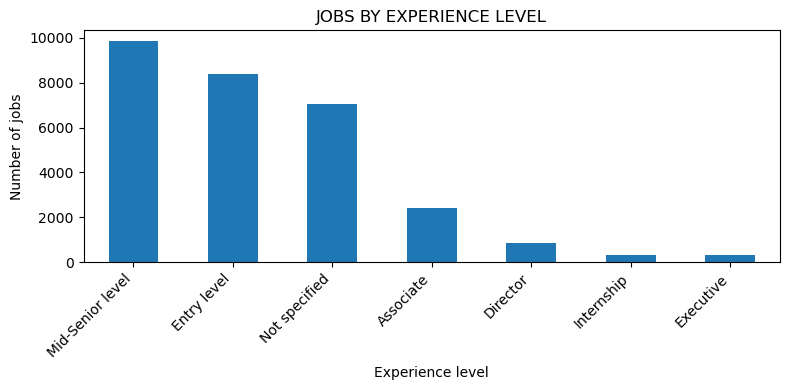

In [98]:
# bar chart
plt.figure(figsize=(8, 4))
counts.plot(kind="bar")

# title and labels
plt.title("JOBS BY EXPERIENCE LEVEL")
plt.xlabel("Experience level")
plt.ylabel("Number of jobs")

# tidy x labels
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

# show chart
plt.show()

### Why the Experience Level Chart Matters

- Experience level is how the model can tell senior jobs from entry-level ones, which is the accountant-versus-cashier problem.
- The chart shows the data has plenty of Mid-Senior and Entry level jobs, but very few Director, Internship and Executive jobs.
- About 24% of jobs have no level stated, so seniority cannot be checked for them.
 ### Experience Level

- Most jobs are Mid-Senior level or Entry level, followed by jobs with no level stated ("Not specified").
- Associate, Director, Internship and Executive jobs are much rarer.
- About 24% of jobs (7,047 of 29,202) have no experience level, so the model cannot match them on seniority.

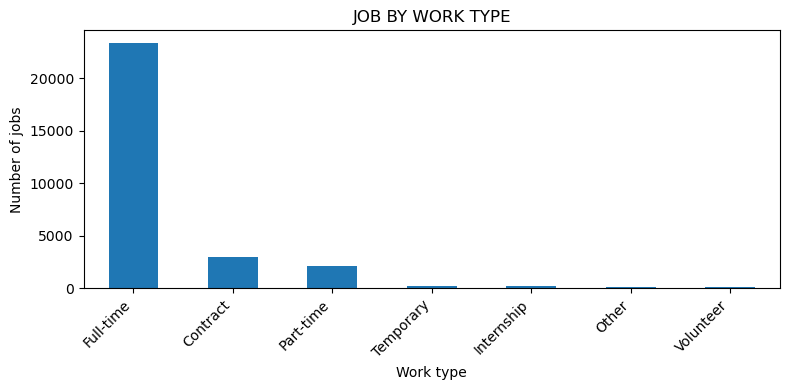

In [99]:
# count each work type
counts = wm["formatted_work_type"].value_counts()

# bar chart
plt.figure(figsize=(8, 4))
counts.plot(kind="bar")

# title and labels
plt.title("JOB BY WORK TYPE")
plt.xlabel("Work type")
plt.ylabel("Number of jobs")

# tidy x labels
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

# show chart
plt.show()

### Work Type
- Full-time jobs make up about 80% of the data. Contract and Part-time follow, and Temporary, Internship, Other and Volunteer are very rare.

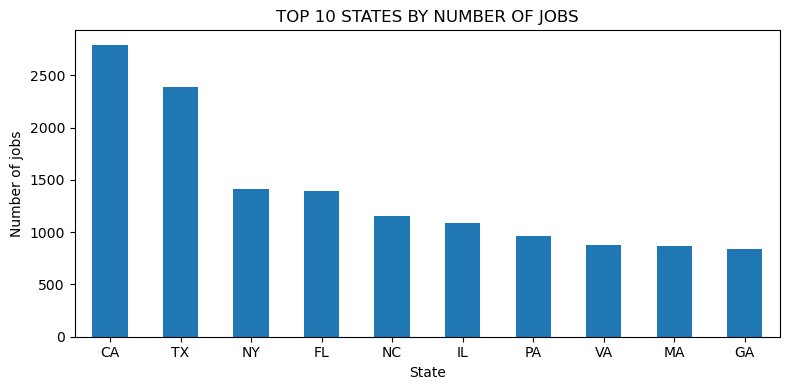

In [100]:
# count jobs per state, leave out Other
counts = wm.loc[wm["state"] != "Other", "state"].value_counts().head(10)

# bar chart
plt.figure(figsize=(8, 4))
counts.plot(kind="bar")

# title and labels
plt.title("TOP 10 STATES BY NUMBER OF JOBS")
plt.xlabel("State")
plt.ylabel("Number of jobs")

# keep state codes upright
plt.xticks(rotation=0)
plt.tight_layout()

# show chart
plt.show()

### Jobs by State
- California, Texas and New York have the most jobs, followed by Florida, North Carolina and Illinois.
- The chart leaves out "Other" (15.4% of rows), which holds jobs with no state code, so it covers about 85% of the data.

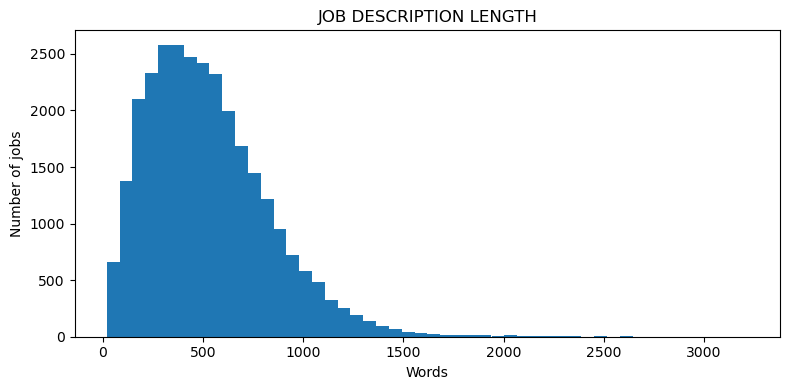

In [101]:
# word count per description
wl = wm["job_description"].str.split().str.len()

# histogram
plt.figure(figsize=(8, 4))
plt.hist(wl, bins=50)

# title and labels
plt.title("JOB DESCRIPTION LENGTH")
plt.xlabel("Words")
plt.ylabel("Number of jobs")

# show chart
plt.tight_layout()
plt.show()

### Description Length
- A histogram was used because description length is a continuous number. It groups the lengths into ranges, so the spread and the long tail are easy to see.
- Most descriptions have between about 300 and 700 words, with a median near 480.
- A few are much longer, up to about 3,000 words. These were kept, since long descriptions are real jobs.

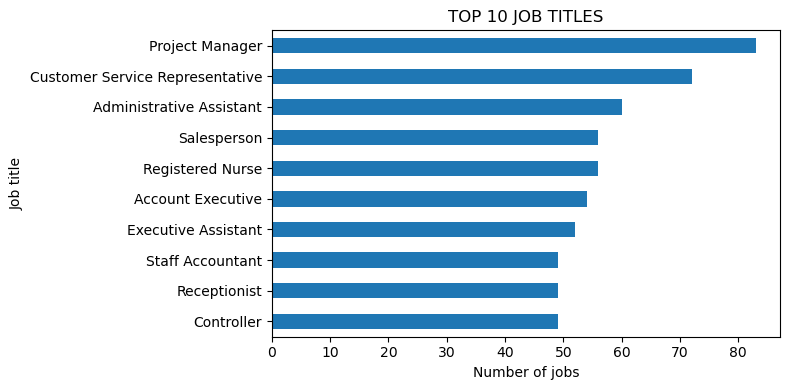

In [102]:
# count titles, top 10
counts = wm["title"].value_counts().head(10)

# horizontal bar chart (biggest on top)
plt.figure(figsize=(8, 4))
counts.sort_values().plot(kind="barh")

# title and labels
plt.title("TOP 10 JOB TITLES")
plt.xlabel("Number of jobs")
plt.ylabel("Job title")

# show chart
plt.tight_layout()
plt.show()

In [103]:
# number of different titles
print(wm["title"].nunique())

21959


### Top Job Titles

- There are 21,959 different job titles, so no single title dominates. The most common titles appear only a small number of times.
- The most common titles are [list the top 3 from the chart].
- The model therefore matches on the title and description text and not on exact title names.

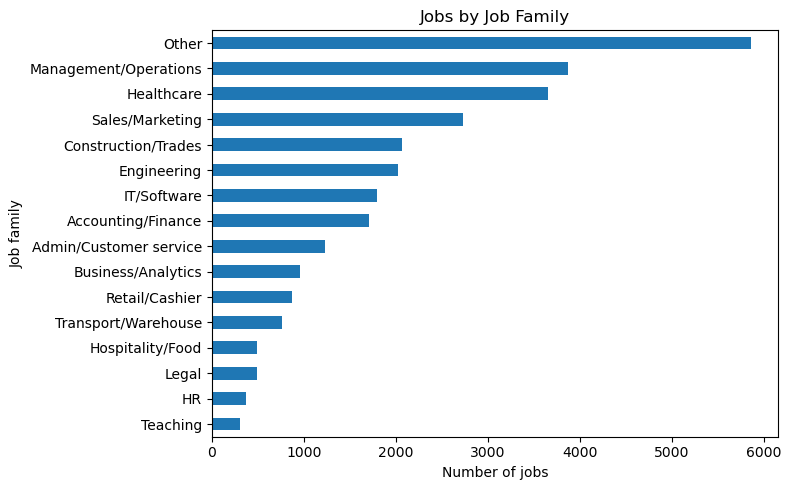

In [104]:
# jobs per family
counts = wm["job_family"].value_counts()

# horizontal bar chart (biggest on top)
plt.figure(figsize=(8, 5))
counts.sort_values().plot(kind="barh")

# title and labels
plt.title("Jobs by Job Family")
plt.xlabel("Number of jobs")
plt.ylabel("Job family")

# show chart
plt.tight_layout()
plt.show()

### Jobs by Job Family

- Management/Operations , Healthcare and Sales/Marketing are the biggest families.
-  "Other"  holds titles with no matching keyword.
- Teaching is the smallest family.

In [105]:
from sklearn.feature_extraction.text import CountVectorizer

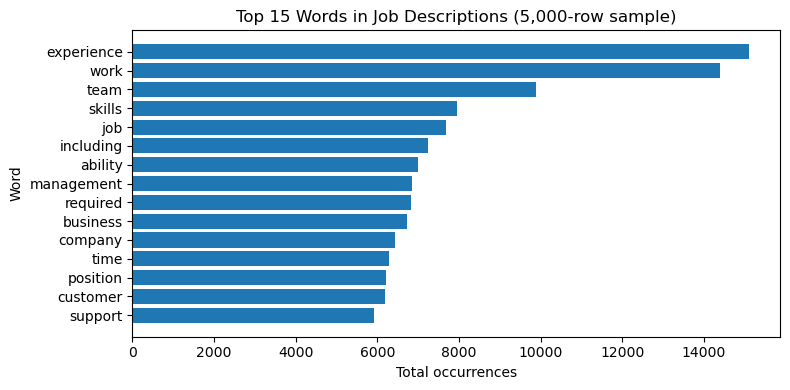

In [106]:
# count words, drop common english words, keep top 5000
cv = CountVectorizer(stop_words="english", max_features=5000)

# fit on a 5,000 row sample (faster)
X = cv.fit_transform(wm["job_description"].sample(5000, random_state=1))

# total count per word
totals = X.sum(axis=0).A1

# top 15 words
top = sorted(zip(cv.get_feature_names_out(), totals), key=lambda x: -x[1])[:15]

# split words and counts
words, counts = zip(*top)

# horizontal bar chart
plt.figure(figsize=(8, 4))
plt.barh(words[::-1], counts[::-1])

# title and labels
plt.title("Top 15 Words in Job Descriptions (5,000-row sample)")
plt.xlabel("Total occurrences")
plt.ylabel("Word")

# show chart
plt.tight_layout()
plt.show()

### Description Length by Experience Level

- Director  and Executive descriptions are about 100 words longer than Entry leveland Mid-Senior .
- Associate  and "Not specified"  are the shortest.
- These groups are small (Director, Executive , so this does not raise the overall correlation (0.05). Length is a weak signal of seniority and is not used to decide it.

In [107]:
# new table for numbers
num = pd.DataFrame()

# words in description
num["desc_words"] = wm["job_description"].str.split().str.len()

# words in title
num["title_words"] = wm["title"].str.split().str.len()

# experience level as a rank (Not specified stays blank)
rank = {"Internship": 0, "Entry level": 1, "Associate": 2,
        "Mid-Senior level": 3, "Director": 4, "Executive": 5}
num["exp_rank"] = wm["formatted_experience_level"].map(rank)

### CORRELATION MATRIX

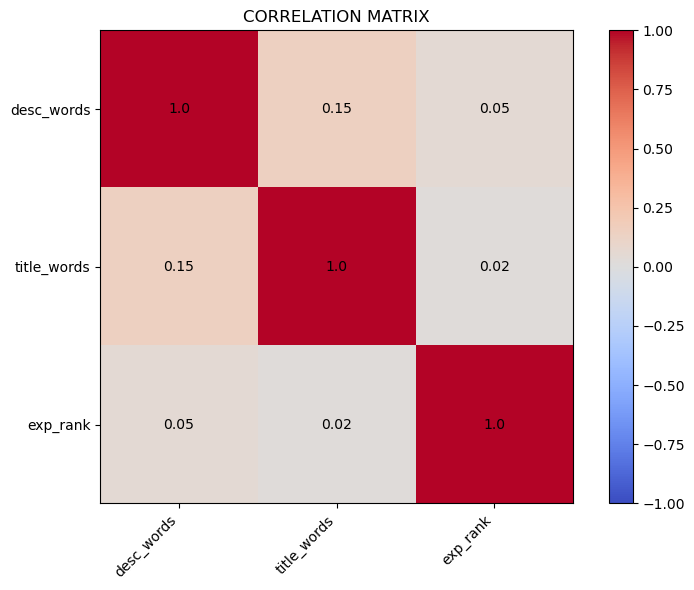

In [108]:
corr = num.corr()

# heatmap, fixed scale -1 to 1
plt.figure(figsize=(8, 6))
plt.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
plt.colorbar()

# axis labels
plt.xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr)), corr.columns)

# print each value in its cell
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, round(corr.iloc[i, j], 2), ha="center", va="center")

# title and show
plt.title("CORRELATION MATRIX")
plt.tight_layout()
plt.show()

### Correlation Matrix

- Description length and title length have a weak positive correlation (0.15).
- Experience level rank has almost no correlation with description length (0.05) or title length (0.02).
- This is probably because only Director and Executive jobs (about 5% of the rows with a level) have clearly longer descriptions. Length is a weak signal of seniority, so seniority is read from the text and the experience level.
- Experience level rank uses 22,155 rows, since "Not specified" rows have no rank.

In [109]:
# parts list
parts = []

# read id + original_listed_time in chunks
for chunk in pd.read_csv(postings_path, usecols=["job_id", "original_listed_time"], chunksize=50000):
    # keep only job_ids in wm
    parts.append(chunk[chunk["job_id"].isin(wm["job_id"])])

In [110]:
# join into wo
wo = pd.concat(parts, ignore_index=True)

# convert from milliseconds to dates
wo["date"] = pd.to_datetime(wo["original_listed_time"], unit="ms")

# blanks
print(wo["date"].isnull().sum())

# earliest and latest
print(wo["date"].min(), wo["date"].max())

# jobs per month
print(wo.set_index("date").resample("MS").size())

0
2023-12-05 21:08:53 2024-04-20 00:24:25
date
2023-12-01        1
2024-01-01        2
2024-02-01        3
2024-03-01      425
2024-04-01    28771
Freq: MS, dtype: int64


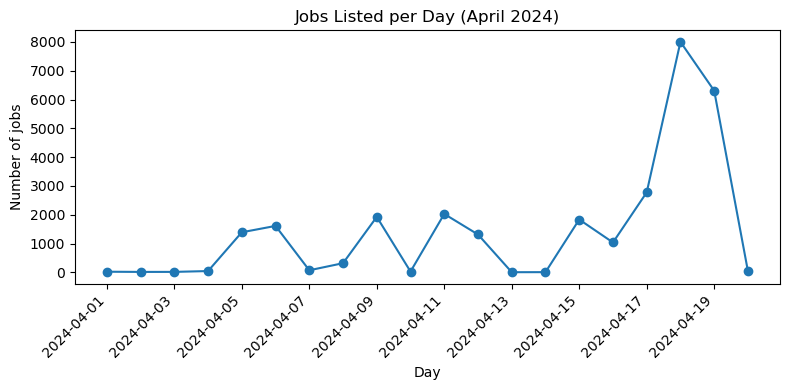

In [111]:
# keep April 2024 only
apr = wo[(wo["date"] >= "2024-04-01") & (wo["date"] < "2024-05-01")]

# jobs per day
daily = apr.set_index("date").resample("D").size()

# line chart
plt.figure(figsize=(8, 4))
plt.plot(daily.index, daily.values, marker="o")

# title and labels
plt.title("Jobs Listed per Day (April 2024)")
plt.xlabel("Day")
plt.ylabel("Number of jobs")

# show chart
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Time Coverage
- Most of jobs were listed in April 2024 (28,771 of 29,202), with only a few older postings from December 2023 to March 2024.
- The data is a snapshot of about two weeks, not a long period, so no trend over time can be shown.
- A time trend is listed as a limitation.

### segment comparisons

formatted_work_type         Contract  Full-time  Internship  Other  Part-time  \
formatted_experience_level                                                      
Associate                       14.6       77.7         0.1    0.0        3.0   
Director                         3.6       94.6         0.0    0.3        1.4   
Entry level                      5.2       80.3         0.2    0.6       12.5   
Executive                        2.2       94.6         0.0    0.3        1.9   
Internship                       0.9       53.8        34.3    0.0        9.5   
Mid-Senior level                12.8       80.6         0.1    0.3        5.1   
Not specified                   12.2       78.5         1.3    0.5        6.3   

formatted_work_type         Temporary  Volunteer  
formatted_experience_level                        
Associate                         1.1        3.6  
Director                          0.1        0.0  
Entry level                       1.1        0.0  
Executive      

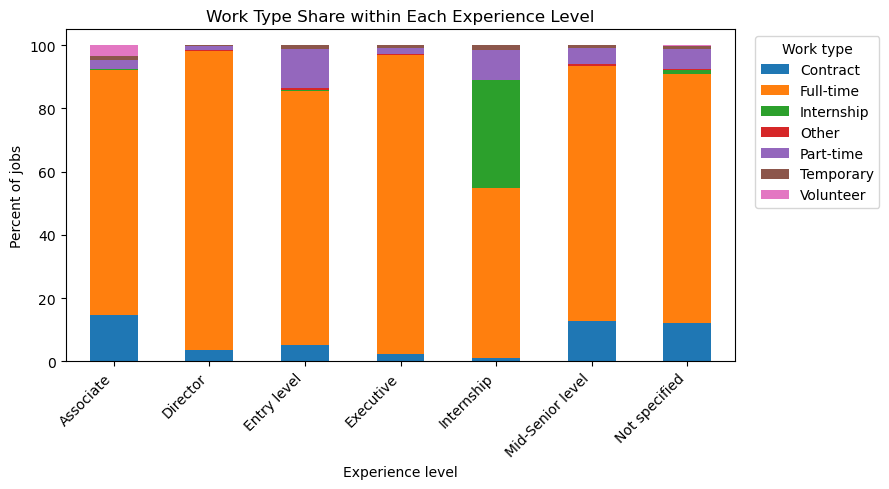

In [112]:
# share of each work type within each experience level (rows add to 100)
ct = pd.crosstab(wm["formatted_experience_level"], wm["formatted_work_type"], normalize="index") * 100

# print rounded table
print(ct.round(1))

# stacked bar chart
ct.plot(kind="bar", stacked=True, figsize=(9, 5))

# title and labels
plt.title("Work Type Share within Each Experience Level")
plt.xlabel("Experience level")
plt.ylabel("Percent of jobs")

# legend outside the chart
plt.legend(title="Work type", bbox_to_anchor=(1.02, 1), loc="upper left")

# show chart
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Experience Level by Work Type

- Full-time is the main work type at every level (78% or more), except Internship (53.8%).
- Director and Executive jobs are almost all full-time (94.6%). Contract is most common for Associate (14.6%) and Mid-Senior (12.8%), and part-time for Entry level (12.5%).
- Only 34.3% of Internship-level jobs have the Internship work type, so the two columns do not always agree.
- Internship, Director and Executive are small groups, so their percentages are less reliable.

In [113]:
# word count per description
wl = wm["job_description"].str.split().str.len()

# group by experience level
g = wl.groupby(wm["formatted_experience_level"])

# count, mean, median per level
print(g.agg(["count", "mean", "median"]).round(1))

                            count   mean  median
formatted_experience_level                      
Associate                    2419  473.6   413.0
Director                      868  646.5   609.5
Entry level                  8371  537.7   501.0
Executive                     317  659.4   612.0
Internship                    338  554.3   514.0
Mid-Senior level             9842  547.9   502.0
Not specified                7047  472.1   415.0


### MODELING AND ANALYTICAL TECHNIQUES

In [114]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

### SPLIT INTO TRAINING AND TESTING

### Variables

- **Dependent variable (Y):** `formatted_experience_level` (six levels: Internship, Entry level, Associate, Mid-Senior level, Director, Executive).
- **Independent variables (X):** `text` (job title and description, converted with TF-IDF), `formatted_work_type` and `state` (both one-hot encoded).
- Jobs with no experience level were left out.

In [115]:
# keep rows with a real level
known = wm[wm["formatted_experience_level"] != "Not specified"]
X = known[["text", "formatted_work_type", "state"]]

# target: experience level
y = known["formatted_experience_level"]

In [116]:
#Spliting the Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [117]:
# sizes
print(X_train.shape, X_test.shape)

# class counts in train
print(y_train.value_counts())

(17724, 3) (4431, 3)
formatted_experience_level
Mid-Senior level    7885
Entry level         6644
Associate           1939
Director             718
Internship           277
Executive            261
Name: count, dtype: int64


### text to numbers
-TF-IDF

In [118]:
# text to numbers (top 5000 words)
tfidf_part = TfidfVectorizer(stop_words="english", max_features=5000)

# categories to 0/1 columns
onehot_part = OneHotEncoder(handle_unknown="ignore")

# apply each to its own columns
prep = ColumnTransformer([
    ("cat", onehot_part, ["formatted_work_type", "state"]),
    ("text", tfidf_part, "text"),
])

In [119]:
# preprocessing + model in one pipeline
rf = Pipeline([
    ("prep", prep),
    ("model", RandomForestClassifier(n_estimators=100, class_weight="balanced",
                                     random_state=42, n_jobs=-1)),
])

In [120]:
# train on training rows only
rf.fit(X_train, y_train)

# predict on test rows
pred = rf.predict(X_test)

# accuracy
print("accuracy:", round(accuracy_score(y_test, pred), 3))

accuracy: 0.68


In [121]:
# precision, recall, f1 per level
print(classification_report(y_test, pred, zero_division=0))

                  precision    recall  f1-score   support

       Associate       0.80      0.13      0.23       480
        Director       0.81      0.09      0.16       150
     Entry level       0.75      0.72      0.74      1727
       Executive       1.00      0.05      0.10        56
      Internship       0.91      0.49      0.64        61
Mid-Senior level       0.63      0.85      0.72      1957

        accuracy                           0.68      4431
       macro avg       0.82      0.39      0.43      4431
    weighted avg       0.71      0.68      0.65      4431



In [122]:
# copy tool and second model
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression

# fresh copy of the same preprocessing
lr = Pipeline([
    ("prep", clone(prep)),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

# train on training rows only
lr.fit(X_train, y_train)

# predict on test rows
pred_lr = lr.predict(X_test)

# accuracy
print("accuracy:", round(accuracy_score(y_test, pred_lr), 3))

# precision, recall, f1 per level
print(classification_report(y_test, pred_lr, zero_division=0))
# precision, recall, f1 per level, as a table
pd.DataFrame(classification_report(y_test, pred_lr, zero_division=0, output_dict=True)).T.round(2)

accuracy: 0.652
                  precision    recall  f1-score   support

       Associate       0.34      0.55      0.42       480
        Director       0.42      0.74      0.53       150
     Entry level       0.75      0.75      0.75      1727
       Executive       0.32      0.59      0.42        56
      Internship       0.67      0.85      0.75        61
Mid-Senior level       0.77      0.58      0.66      1957

        accuracy                           0.65      4431
       macro avg       0.54      0.68      0.59      4431
    weighted avg       0.70      0.65      0.66      4431



,precision,recall,f1-score,support
Associate,0.34,0.55,0.42,480.00
Director,0.42,0.74,0.53,150.00
Entry level,0.75,0.75,0.75,1727.00
Executive,0.32,0.59,0.42,56.00
Internship,0.67,0.85,0.75,61.00
Mid-Senior level,0.77,0.58,0.66,1957.00
accuracy,0.65,0.65,0.65,0.65
macro avg,0.54,0.68,0.59,4431.00
weighted avg,0.70,0.65,0.66,4431.00


In [123]:
# confusion matrix for logistic regression
from sklearn.metrics import confusion_matrix

# levels in order
labels = ["Internship", "Entry level", "Associate", "Mid-Senior level", "Director", "Executive"]

# build the table (rows = real level, columns = predicted)
cm = pd.DataFrame(confusion_matrix(y_test, pred_lr, labels=labels),
                  index=labels, columns=labels)

# show as a table
cm

,Internship,Entry level,Associate,Mid-Senior level,Director,Executive
Internship,52,7,0,2,0,0
Entry level,15,1301,187,198,17,9
Associate,2,87,264,105,14,8
Mid-Senior level,9,332,325,1130,118,43
Director,0,7,4,18,111,10
Executive,0,1,2,14,6,33


In [124]:
# test rows predicted as Director/Executive that are really Entry level
bad = X_test[(y_test == "Entry level") & (pred_lr == "Director")]

# show 5 titles
print(bad["text"].str[:80].head(5).values)

['OMNI Dir Human Resources Omni Air International is a private airline providing t'
 'Customer Success Advocate I About Lumen\n\nLumen connects the world. We are igniti'
 'Procurement Motorization Hunter Douglas is the world’s leading manufacturer of w'
 'Pharmacist, Clinical/MTM Job Description\n\nJob Summary\n\nMolina Pharmacy Services/'
 'COOK Cooks provide assistance to the Food Service Director in planning, organizi']


In [125]:
# import scorer
from sklearn.metrics import f1_score

# empty list for results
rows = []

# train and test scores, both models
for name, m in [("Logistic Regression", lr), ("Random Forest", rf)]:
    # predictions on both parts
    p_tr = m.predict(X_train)
    p_te = m.predict(X_test)
    # accuracy and macro f1 saved as one row
    rows.append({
        "Model": name,
        "Train accuracy": round(accuracy_score(y_train, p_tr), 3),
        "Test accuracy": round(accuracy_score(y_test, p_te), 3),
        "Train macro f1": round(f1_score(y_train, p_tr, average="macro"), 3),
        "Test macro f1": round(f1_score(y_test, p_te, average="macro"), 3),
    })

# make the table
results = pd.DataFrame(rows)
results

,Model,Train accuracy,Test accuracy,Train macro f1,Test macro f1
0,Logistic Regression,0.737,0.652,0.73,0.588
1,Random Forest,1.000,0.680,1.00,0.430


In [126]:
# tuning tool
from sklearn.model_selection import GridSearchCV

# settings to try
grid = {
    "model__C": [0.1, 0.3, 1.0],
    "prep__text__max_features": [2000, 5000],
}

# search with 3-fold cross-validation, scored by macro f1
gs = GridSearchCV(lr, grid, cv=3, scoring="f1_macro", n_jobs=-1)

# fit on training rows only
gs.fit(X_train, y_train)

# best settings and cross-validated score
print(gs.best_params_)
print("cv macro f1:", round(gs.best_score_, 3))

# score the best model on the test rows
best = gs.best_estimator_
p_best = best.predict(X_test)
print("test acc:", round(accuracy_score(y_test, p_best), 3))

{'model__C': 1.0, 'prep__text__max_features': 5000}
cv macro f1: 0.561
test acc: 0.652


In [127]:
# report as a dictionary
rep = classification_report(y_test, p_best, zero_division=0, output_dict=True)

# turn into a table
tbl = pd.DataFrame(rep).T

# remove the accuracy row (reported separately)
tbl = tbl.drop(index="accuracy")

# round scores, make support whole numbers
tbl[["precision", "recall", "f1-score"]] = tbl[["precision", "recall", "f1-score"]].round(2)
tbl["support"] = tbl["support"].astype(int)

# show as a table
tbl

,precision,recall,f1-score,support
Associate,0.34,0.55,0.42,480
Director,0.42,0.74,0.53,150
Entry level,0.75,0.75,0.75,1727
Executive,0.32,0.59,0.42,56
Internship,0.67,0.85,0.75,61
Mid-Senior level,0.77,0.58,0.66,1957
macro avg,0.54,0.68,0.59,4431
weighted avg,0.70,0.65,0.66,4431


In [128]:
# simpler forest: shallower trees, bigger leaves
rf2 = Pipeline([
    ("prep", clone(prep)),
    ("model", RandomForestClassifier(n_estimators=200, max_depth=20, min_samples_leaf=5,
                                     class_weight="balanced", random_state=42, n_jobs=-1)),
])

# train on training rows only
rf2.fit(X_train, y_train)

# empty list for results
rows = []

# loop over the models
for name, m in [("Logistic Regression", lr),
                ("Random Forest (default)", rf),
                ("Random Forest (limited depth)", rf2)]:
    # predictions on both parts
    p_tr = m.predict(X_train)
    p_te = m.predict(X_test)
    # one row per model
    rows.append({
        "Model": name,
        "Train accuracy": round(accuracy_score(y_train, p_tr), 3),
        "Test accuracy": round(accuracy_score(y_test, p_te), 3),
        "Train macro f1": round(f1_score(y_train, p_tr, average="macro"), 3),
        "Test macro f1": round(f1_score(y_test, p_te, average="macro"), 3),
    })

# show as a table
pd.DataFrame(rows)

,Model,Train accuracy,Test accuracy,Train macro f1,Test macro f1
0,Logistic Regression,0.737,0.652,0.730,0.588
1,Random Forest (default),1.000,0.680,1.000,0.430
2,Random Forest (limited depth),0.809,0.627,0.863,0.563


### Model Comparison
- Random Forest (default) scores 1.00 on the training jobs but only 0.43 macro f1 on the test jobs, so it is overfitting badly.
- Limiting tree depth reduced the gap (macro f1 0.863 on training, 0.563 on test), but some overfitting remains.
- Logistic Regression has the best test macro f1 (0.588) and the smallest gap between training and test (0.14), so it was kept as the final model.
- Random Forest (default) has the highest test accuracy (0.68), but this comes mostly from the two largest levels.

In [129]:
# confusion matrix for logistic regression
from sklearn.metrics import confusion_matrix

# levels in order
labels = ["Internship", "Entry level", "Associate", "Mid-Senior level", "Director", "Executive"]

# build the table (rows = real level, columns = predicted)
cm = pd.DataFrame(confusion_matrix(y_test, pred_lr, labels=labels),
                  index=labels, columns=labels)

# show as a table
cm

,Internship,Entry level,Associate,Mid-Senior level,Director,Executive
Internship,52,7,0,2,0,0
Entry level,15,1301,187,198,17,9
Associate,2,87,264,105,14,8
Mid-Senior level,9,332,325,1130,118,43
Director,0,7,4,18,111,10
Executive,0,1,2,14,6,33


### Confusion Matrix (Logistic Regression)
- Most correct predictions: Entry level (1,301 of 1,727), Mid-Senior (1,130 of 1,957), Director (111 of 150), Internship (52 of 61) and Executive (33 of 56).
- Most errors are between neighbouring levels: Mid-Senior predicted as Entry level (332) or Associate (325), and Entry level predicted as Mid-Senior (198) or Associate (187).
- Large seniority mistakes are rare. For example, only 7 Entry level jobs were predicted as Director and 9 as Executive.

In [130]:
# feature names from the preprocessing
names = lr.named_steps["prep"].get_feature_names_out()

# model weights per level
coefs = lr.named_steps["model"].coef_

# levels in the same order as the rows of coefs
levels = lr.named_steps["model"].classes_

# empty list for rows
rows_kw = []

In [131]:
# show full text in table cells
pd.set_option("display.max_colwidth", None)

In [132]:
# empty list for rows (reset every run)
rows_kw = []

# top 8 features per level
for i, lev in enumerate(levels):
    top = np.argsort(coefs[i])[-8:][::-1]
    # clean the prefixes
    words = [names[j].replace("text__", "").replace("cat__", "") for j in top]
    rows_kw.append({"Level": lev, "Top words": ", ".join(words)})

# make the table
key_words = pd.DataFrame(rows_kw)
# show as a table without row numbers
key_words.style.hide(axis="index")

Level,Top words
Associate,"associate, specialist, formatted_work_type_Volunteer, aon, abbott, accountant, topgolf, coordinator"
Director,"director, controller, leadership, ge, 10, oversee, farm, management"
Entry level,"specialist, coordinator, entry, assistant, engineer, lpn, technician, dice"
Executive,"vice, president, vp, general, executive, cfo, board, chief"
Internship,"intern, trainee, apprentice, internship, student, enrolled, summer, learn"
Mid-Senior level,"manager, rn, senior, sr, supervisor, nurse, technologist, experience"


### Modelling Summary

- **Technique:** classification, predicting `formatted_experience_level` (six levels) from the job text, work type and state. Jobs with no level were left out, leaving 22,155 jobs (17,724 for training and 4,431 for testing).
- **Models compared:** Logistic Regression, Random Forest (default) and Random Forest (limited depth).
- **Final model:** Logistic Regression, with accuracy 0.652 and macro f1 0.588. It had the best macro f1 and the smallest gap between training and test scores. Random Forest (default) had the highest accuracy (0.68) but overfitted (training accuracy 1.00, test macro f1 0.43).
- **Strengths:** Entry level (f1 0.75) and Internship (0.75) are predicted best, and large seniority mistakes are rare (for example only 7 Entry level jobs predicted as Director).
- **Weaknesses:** most errors are between neighbouring levels (Entry level, Associate and Mid-Senior). Associate and Executive are weakest (f1 0.42 each). Internship (61 jobs) and Executive (56 jobs) have few test jobs, so their scores are less reliable.
- **Key drivers:** title words such as "vice", "president", "intern", "director" and "manager" drive the predictions. Some top words are company names, so part of the model reflects employers.
- **Limits:** the data is a snapshot of about two weeks, all United States, with no Kenyan jobs. Results come from one train/test split, and the labels are chosen by employers, so they are not always consistent.